# 04 — Regresi & Prediksi (v3)

Tiga model, masing-masing menjawab satu pertanyaan dan **dievaluasi dengan cara yang jujur**:

| # | pertanyaan | unit | evaluasi |
|---|---|---|---|
| M1 | Berapa **nilai produksi** (Rp) untuk volume & komoditas tertentu? (+ elastisitas untuk simulator dashboard) | kab × komoditas × tahun | grouped-CV per **kabupaten** |
| M2 | Berapa produksi **yang wajar** bagi kabupaten dengan pembudidaya, komposisi, habitat — dan kini **luas lahan**? | kab × tahun | grouped-CV per **kabupaten**, *semua set dibandingkan pada sampel yang sama* |
| M3 | **Prakiraan produksi tahun depan** per kabupaten | kab × tahun | **rolling-origin** + validasi ke tahun baru bila ada |

**Perubahan v3**
* Tahun terakhir, tahun uji, horizon proyeksi, dan "outlier" **dihitung dari data** (tidak ada `2024`, `2025`, `Sumenep` yang ditulis keras).
* **Luas lahan** masuk M2 sebagai set **S4** bila lolos `feature_registry`; keputusan dipilih oleh CV pada sampel yang sama, dengan aturan *pilih set paling sederhana yang R²-nya tidak kalah >0,01*.
* `regression_eval.csv` ditulis dengan **skema yang dibaca dashboard** (`dataset, model, cv_r2_mean, r2_test, coef`); tabel lengkap ada di `regression_eval_detail.csv`.
* Tiap blok punya penjaga data minimum: bila data terlalu sedikit, bagian itu **dilewati dengan pesan** (bukan error).

In [2]:
import os, warnings; warnings.filterwarnings('ignore')
import json, hashlib, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib
from pathlib import Path
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge, HuberRegressor, LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score

PROC = Path('../data/processed'); REP = Path('../output/reports'); FIG = Path('../output/figures'); MODEL = Path('../output/models')
for d in (REP, FIG, MODEL): d.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid'); pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)
FAST = os.environ.get('PIPE_FAST') == '1'; N_TREE = 100 if FAST else 300; N_BOOT = 60 if FAST else 200; REPEATS = 2 if FAST else 5

rk  = pd.read_parquet(PROC / 'reg_komoditas.parquet').reset_index(drop=True)
pan = pd.read_parquet(PROC / 'panel_kab_tahun.parquet').sort_values(['kabupaten', 'tahun']).reset_index(drop=True)
F   = pd.read_parquet(PROC / 'features_kab.parquet'); vnew = pd.read_parquet(PROC / 'validasi_produksi_tahun_baru.parquet')
reg = pd.read_csv(REP / 'feature_registry.csv').set_index('fitur'); OUTLIER_KAB = json.load(open(REP / 'eda_meta.json'))['outlier_kab']
YEARS = sorted(int(y) for y in pan.tahun.unique()); LAST = YEARS[-1]
print(f'reg_komoditas {rk.shape} | panel {pan.shape} | tahun {YEARS} | LAST={LAST} | outlier struktural: {OUTLIER_KAB}')

def metrics(y, p, mask=None):
    '''y, p dalam skala log. R2_asli = R2 pada skala asli (dipakai kolom r2_test dashboard); medAPE tahan bias retransformasi.'''
    if mask is not None: y, p = y[mask], p[mask]
    return dict(R2_log=r2_score(y, p), R2_asli=r2_score(np.exp(y), np.exp(p)), RMSE_log=float(np.sqrt(np.mean((y - p) ** 2))),
                MAE_asli=float(np.mean(np.abs(np.exp(y) - np.exp(p)))), medAPE=float(np.median(np.abs(np.exp(p) - np.exp(y)) / np.exp(y))))

def oof_grouped(model, X, y, groups, n_splits=5, repeats=REPEATS, seed=0):
    '''Grouped K-fold berulang: seluruh baris satu kabupaten selalu di fold yang sama -> (repeats, n) prediksi out-of-fold.'''
    ug = np.array(sorted(set(groups))); n_splits = min(n_splits, len(ug)); out = np.zeros((repeats, len(y)))
    for r in range(repeats):
        fold_of = dict(zip(ug, np.random.default_rng(seed + r).permutation(len(ug)) % n_splits)); f = np.array([fold_of[g] for g in groups])
        for k in range(n_splits):
            tr, te = np.where(f != k)[0], np.where(f == k)[0]; out[r, te] = clone(model).fit(X.iloc[tr], y[tr]).predict(X.iloc[te])
    return out

def summarize(name, y, oof, mask=None):
    d = pd.DataFrame([metrics(y, oof[r], mask) for r in range(oof.shape[0])])
    return {'model': name, **{c: d[c].mean() for c in d}, **{c + '_sd': d[c].std() for c in ['R2_log', 'medAPE']}}

reg_komoditas (1353, 7) | panel (190, 32) | tahun [2020, 2021, 2022, 2023, 2024] | LAST=2024 | outlier struktural: ['Pacitan', 'Probolinggo', 'Situbondo', 'Sumenep']


## M1 — Nilai produksi ~ volume + komoditas
Nilai = volume × harga, jadi R² tinggi *memang diharapkan* begitu komoditas (penentu harga) masuk. Kegunaan: **estimasi nilai bila harga tak tersedia, deteksi data janggal (residual besar), dan elastisitas untuk simulator dashboard.**

In [3]:
y1 = rk.l_nilai.values; g1 = rk.kabupaten.values
def prep(num, cat=()):
    tr = [('num', StandardScaler(), list(num))]
    if cat: tr.append(('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=5), list(cat)))
    return ColumnTransformer(tr)
M1 = {'Volume saja (Ridge)': (Pipeline([('p', prep(['l_vol'])), ('m', Ridge(1.0))]), ['l_vol']),
      'Volume + komoditas (Ridge)': (Pipeline([('p', prep(['l_vol'], ['komoditas'])), ('m', Ridge(1.0))]), ['l_vol', 'komoditas']),
      'Volume + komoditas (Huber)': (Pipeline([('p', prep(['l_vol'], ['komoditas'])), ('m', HuberRegressor(alpha=1e-3, max_iter=2000))]), ['l_vol', 'komoditas']),
      'Volume + komoditas (RandomForest)': (Pipeline([('p', prep(['l_vol'], ['komoditas'])), ('m', RandomForestRegressor(N_TREE, min_samples_leaf=3, random_state=0, n_jobs=-1))]), ['l_vol', 'komoditas'])}
res1, oof1 = [], {}
for nm, (mdl, cols) in M1.items(): oof1[nm] = oof_grouped(mdl, rk[cols], y1, g1); res1.append(summarize(nm, y1, oof1[nm]))
res1 = pd.DataFrame(res1).set_index('model'); res1.insert(0, 'tugas', 'M1 nilai'); display(res1.round(3))

,tugas,R2_log,R2_asli,RMSE_log,MAE_asli,medAPE,R2_log_sd,medAPE_sd
model,,,,,,,,
Volume saja (Ridge),M1 nilai,0.928,-2.305,0.779,53393.390,0.342,0.000,0.005
Volume + komoditas (Ridge),M1 nilai,0.979,0.789,0.424,14484.767,0.134,0.002,0.003
Volume + komoditas (Huber),M1 nilai,0.978,0.831,0.425,13795.916,0.133,0.004,0.003
Volume + komoditas (RandomForest),M1 nilai,0.944,0.430,0.687,29978.215,0.267,0.002,0.004


In [4]:
# Elastisitas: cluster-bootstrap per kabupaten (log-log, OLS) tanpa & dengan komoditas
def elastisitas(df, dengan_kom):
    X = pd.get_dummies(df[['l_vol', 'komoditas']], columns=['komoditas'], drop_first=True, dtype=float) if dengan_kom else df[['l_vol']]
    return LinearRegression().fit(X, df.l_nilai).coef_[list(X.columns).index('l_vol')]
rng = np.random.default_rng(0); kabs_ = rk.kabupaten.unique(); groups_ = {k: d for k, d in rk.groupby('kabupaten')}; el = {}
for dk in [False, True]:
    b = [elastisitas(pd.concat([groups_[k] for k in rng.choice(kabs_, len(kabs_), replace=True)]), dk) for _ in range(N_BOOT)]
    el[dk] = (elastisitas(rk, dk), *np.percentile(b, [2.5, 97.5]))
for dk, (pt, lo, hi) in el.items(): print(f"Elastisitas {'DENGAN' if dk else 'TANPA'} komoditas: {pt:.3f} (95% CI bootstrap per kab: {lo:.3f} – {hi:.3f})")
print(f'Interpretasi: +1% volume -> ~+{el[True][0]:.2f}% nilai (komoditas tetap).')

Elastisitas TANPA komoditas: 0.944 (95% CI bootstrap per kab: 0.920 – 0.974)
Elastisitas DENGAN komoditas: 0.974 (95% CI bootstrap per kab: 0.959 – 0.990)
Interpretasi: +1% volume -> ~+0.97% nilai (komoditas tetap).


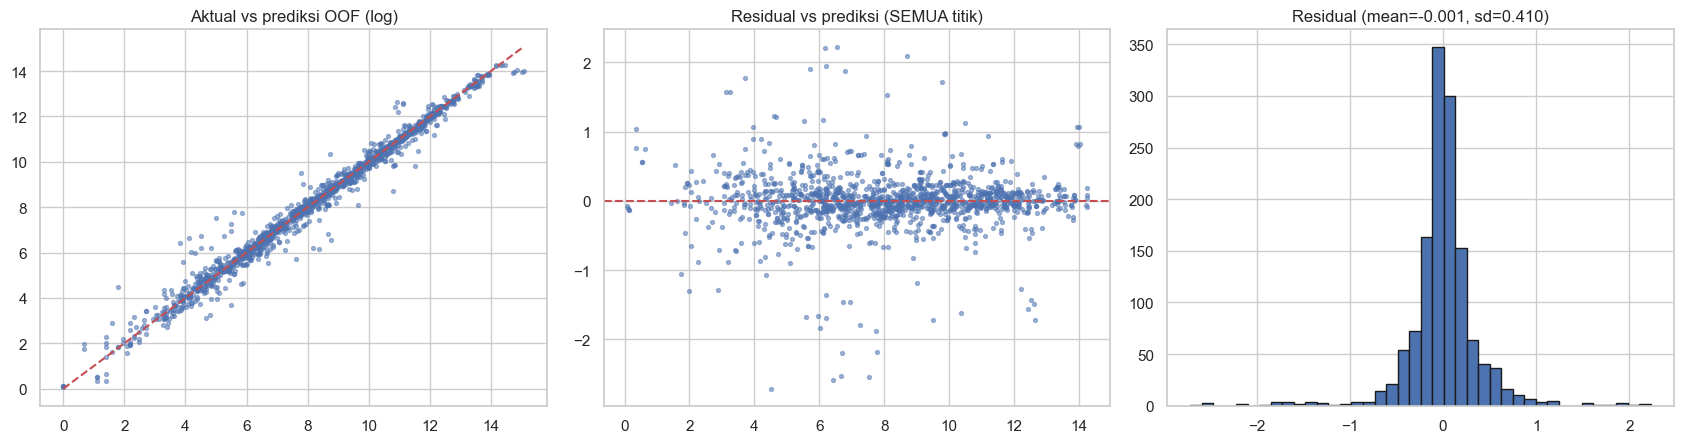

Selisih terbesar (kandidat dicek ke dinas — bukan otomatis dibuang):


,tahun,kabupaten,komoditas,vol_ton,nilai_juta,pred_nilai_juta,resid_log
503,2021,Probolinggo,KERONG-KERONG,3.17,6.0,90.26,-2.71
215,2020,Probolinggo,KERONG-KERONG,23.00,46.0,610.97,-2.59
219,2020,Probolinggo,TERI,74.16,148.0,1890.82,-2.55
507,2021,Probolinggo,TERI,29.64,62.0,780.39,-2.53
22,2020,Banyuwangi,SIDAT,32.26,6451.0,693.25,2.23
313,2021,Banyuwangi,SIDAT,21.84,4368.0,476.62,2.22
423,2021,Lamongan,SEPAT,30.23,91.0,822.29,-2.20
413,2021,Lamongan,BETOK,89.92,270.0,2381.64,-2.18


In [5]:
best1 = res1.R2_log.idxmax(); p1 = oof1[best1].mean(axis=0); res = y1 - p1
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
ax[0].scatter(y1, p1, s=8, alpha=.5); lim = [y1.min(), y1.max()]; ax[0].plot(lim, lim, 'r--'); ax[0].set_title('Aktual vs prediksi OOF (log)')
ax[1].scatter(p1, res, s=8, alpha=.5); ax[1].axhline(0, color='r', ls='--'); ax[1].set_title('Residual vs prediksi (SEMUA titik)')
ax[2].hist(res, bins=40, edgecolor='k'); ax[2].set_title(f'Residual (mean={res.mean():.3f}, sd={res.std():.3f})')
plt.tight_layout(); plt.savefig(FIG / '04_M1_diagnostik.png', dpi=110); plt.show()
rk['pred_nilai_juta'] = np.exp(p1); rk['resid_log'] = res
print('Selisih terbesar (kandidat dicek ke dinas — bukan otomatis dibuang):'); display(rk.reindex(rk.resid_log.abs().sort_values(ascending=False).index).head(8)[['tahun', 'kabupaten', 'komoditas', 'vol_ton', 'nilai_juta', 'pred_nilai_juta', 'resid_log']].round(2))

## M2 — Produksi “wajar” per kabupaten (struktural)
Tanpa data tahun lalu: seberapa jauh **pembudidaya + komposisi + habitat (+ luas lahan)** menjelaskan skala produksi. Residual = kabupaten di atas/bawah ekspektasi.
**Adil:** semua set dievaluasi pada **sampel yang sama** (baris yang lengkap untuk fitur terbanyak), sehingga set dengan luas lahan tidak "menang" hanya karena sampelnya lebih mudah.

In [6]:
hab = F.set_index('kabupaten')[['h_kolam', 'h_tambak', 'h_laut']]
d2 = pan.join(hab, on='kabupaten').reset_index(drop=True)
for c in ['h_kolam', 'h_tambak', 'h_laut']: d2[c] = d2[c].fillna(d2[c].median())
share = [c for c in d2.columns if c.startswith('share_') and d2[c].std() > 0]
if 'share_lainnya' in share: share.remove('share_lainnya')
elif share: share = share[:-1]                                   # share berjumlah 1 -> buang satu (acuan) agar tidak kolinear sempurna
S = {'S1 pembudidaya': ['l_pembudidaya'], 'S2 + komposisi komoditas': ['l_pembudidaya', 'shannon'] + share}
S['S3 + habitat'] = S['S2 + komposisi komoditas'] + ['h_kolam', 'h_tambak', 'h_laut']
luas_ok = bool(reg.loc['luas_lahan_ha', 'usable_panel']) and d2.l_luas.notna().sum() >= 40
if luas_ok: S['S4 + luas lahan'] = S['S3 + habitat'] + ['l_luas']
need = sorted(set(sum(S.values(), []))); d2c = d2.dropna(subset=need).reset_index(drop=True)
M2_OK = len(d2c) >= 30 and d2c.kabupaten.nunique() >= 10
print(f'Sampel bersama untuk M2: {len(d2c)} baris dari {len(d2)} ({d2c.kabupaten.nunique()} kab) | set: {list(S)}' + ('' if luas_ok else ' | luas lahan belum memadai -> S4 tidak diuji'))

MD = {'Ridge': Ridge(3.0), 'Huber': HuberRegressor(alpha=1.0, max_iter=3000),
      'RandomForest': RandomForestRegressor(N_TREE, min_samples_leaf=3, random_state=0, n_jobs=-1),
      'GradBoost': GradientBoostingRegressor(n_estimators=150, max_depth=2, learning_rate=0.05, subsample=0.8, random_state=0)}
res2, oof2, best2, set2, res2_tab = [], {}, None, None, None
if M2_OK:
    y2 = d2c.l_produksi_ton.values; g2 = d2c.kabupaten.values; ex_out = ~np.isin(g2, OUTLIER_KAB)
    oof2['Baseline rata-rata'] = oof_grouped(DummyRegressor(), d2c[['l_pembudidaya']], y2, g2)
    r = summarize('Baseline rata-rata', y2, oof2['Baseline rata-rata']); r['medAPE_tanpa_outlier'] = metrics(y2, oof2['Baseline rata-rata'].mean(0), ex_out)['medAPE']; res2.append(r)
    for sn, cols in S.items():
        for mn, m in MD.items():
            nm = f'{sn} | {mn}'; oof2[nm] = oof_grouped(Pipeline([('s', StandardScaler()), ('m', m)]), d2c[cols], y2, g2)
            r = summarize(nm, y2, oof2[nm]); r['medAPE_tanpa_outlier'] = float(np.mean([metrics(y2, oof2[nm][i], ex_out)['medAPE'] for i in range(oof2[nm].shape[0])])); res2.append(r)
    res2_tab = pd.DataFrame(res2).set_index('model'); res2_tab.insert(0, 'tugas', 'M2 produksi struktural')
    display(res2_tab[['R2_log', 'R2_log_sd', 'RMSE_log', 'MAE_asli', 'medAPE', 'medAPE_tanpa_outlier']].sort_values('R2_log', ascending=False).round(3))
else: print('M2 dilewati: data lengkap terlalu sedikit.')

Sampel bersama untuk M2: 190 baris dari 190 (38 kab) | set: ['S1 pembudidaya', 'S2 + komposisi komoditas', 'S3 + habitat'] | luas lahan belum memadai -> S4 tidak diuji


,R2_log,R2_log_sd,RMSE_log,MAE_asli,medAPE,medAPE_tanpa_outlier
model,,,,,,
S1 pembudidaya | Ridge,0.602,0.014,1.322,3.256249e+04,0.778,0.757
S1 pembudidaya | Huber,0.599,0.013,1.327,3.232920e+04,0.774,0.750
S2 + komposisi komoditas | RandomForest,0.579,0.033,1.358,3.116181e+04,0.693,0.645
S3 + habitat | RandomForest,0.573,0.039,1.368,3.106615e+04,0.678,0.639
S2 + komposisi komoditas | GradBoost,0.561,0.051,1.387,3.118530e+04,0.706,0.668
S2 + komposisi komoditas | Ridge,0.550,0.136,1.394,9.569717e+05,0.686,0.646
S2 + komposisi komoditas | Huber,0.536,0.110,1.420,2.704257e+05,0.709,0.681
S3 + habitat | GradBoost,0.535,0.062,1.427,3.121904e+04,0.704,0.662
S1 pembudidaya | GradBoost,0.435,0.050,1.575,4.397927e+04,0.720,0.702


In [7]:
if M2_OK:
    sc = res2_tab.drop('Baseline rata-rata'); sc['set'] = [i.split(' | ')[0] for i in sc.index]
    best_per_set = sc.groupby('set').R2_log.max(); top = best_per_set.max()
    set2 = [s for s in S if s in best_per_set.index and best_per_set[s] >= top - 0.01][0]          # set paling sederhana yang tidak kalah >0.01
    best2 = sc[sc.set == set2].R2_log.idxmax()
    print(f'Set terpilih: {set2} (R2 terbaik antar-set = {top:.3f}; aturan: paling sederhana dalam 0.01) | model: {best2} | R2(log)={res2_tab.loc[best2, "R2_log"]:.3f} | medAPE={res2_tab.loc[best2, "medAPE"]:.3f}')
    if 'S4 + luas lahan' in best_per_set.index: print(f'Nilai tambah luas lahan: S4 {best_per_set["S4 + luas lahan"]:.3f} vs S3 {best_per_set["S3 + habitat"]:.3f} (selisih {best_per_set["S4 + luas lahan"] - best_per_set["S3 + habitat"]:+.3f})')
    d2c['resid_oof'] = y2 - oof2[best2].mean(axis=0)
    rkab = d2c.groupby('kabupaten').agg(produksi_ton=('produksi_ton', 'mean'), resid_log=('resid_oof', 'mean')).sort_values('resid_log'); rkab['produksi_ekspektasi_ton'] = rkab.produksi_ton / np.exp(rkab.resid_log)
    rkab.to_csv(REP / 'produksi_residual_kab.csv'); print('Jauh DI BAWAH ekspektasi:'); display(rkab.head(6).round(2)); print('Jauh DI ATAS ekspektasi:'); display(rkab.tail(6).round(2))

Set terpilih: S1 pembudidaya (R2 terbaik antar-set = 0.602; aturan: paling sederhana dalam 0.01) | model: S1 pembudidaya | Ridge | R2(log)=0.602 | medAPE=0.778
Jauh DI BAWAH ekspektasi:


,produksi_ton,resid_log,produksi_ekspektasi_ton
kabupaten,,,
Sampang,1000.73,-2.28,9772.16
Bondowoso,927.35,-2.15,7940.81
Blitar,17243.93,-1.74,98150.87
Kota Batu,57.69,-1.66,304.31
Kota Malang,150.86,-1.58,735.03
Magetan,1730.79,-1.26,6113.26


Jauh DI ATAS ekspektasi:


,produksi_ton,resid_log,produksi_ekspektasi_ton
kabupaten,,,
Nganjuk,9902.46,1.37,2525.60
Kota Surabaya,9059.22,1.46,2110.93
Situbondo,11797.37,1.64,2285.84
Tuban,46521.07,2.05,5984.05
Sidoarjo,107552.18,2.50,8846.00
Sumenep,692287.33,3.81,15344.16


## M3 — Prakiraan produksi tahun depan (rolling-origin)
Fitur hanya yang **sudah diketahui** pada tahun t−1 (lag dibuat lewat *join tahun−1*, sehingga tahun yang bolong tidak salah dianggap berurutan). Target = pertumbuhan log.
Tolok ukur wajar adalah **baseline naif**; model ML dipakai hanya bila *nyata* mengalahkannya.

In [8]:
lagd = pan[['kabupaten', 'tahun', 'l_produksi_ton', 'l_pembudidaya', 'shannon', 'top_share']].copy(); lagd['tahun'] += 1
lagd.columns = ['kabupaten', 'tahun', 'lag', 'lpem_lag', 'shan_lag', 'top_lag']
g = pan.merge(lagd, on=['kabupaten', 'tahun'], how='left'); g['d'] = g.l_produksi_ton - g.lag; g['ppp_lag'] = g.lag - g.lpem_lag
FE = ['lag', 'lpem_lag', 'shan_lag', 'top_lag', 'ppp_lag']
dd = g.dropna(subset=['lag']).reset_index(drop=True); dd_fe = dd.dropna(subset=FE)
M3_OK = dd.tahun.nunique() >= 2 and len(dd) >= 30
print(f'baris pertumbuhan: {len(dd)} (tahun {sorted(dd.tahun.unique())}) | M3 ' + ('dijalankan' if M3_OK else 'DILEWATI: perlu >=3 tahun data & >=30 baris') + (f' | pertumbuhan log: mean {dd.d.mean():.3f}, sd {dd.d.std():.3f}' if len(dd) else ''))
def mdl_growth(kind):
    if kind == 'Ridge pertumbuhan': return Pipeline([('s', StandardScaler()), ('m', Ridge(10.0))])
    if kind == 'Huber pertumbuhan': return Pipeline([('s', StandardScaler()), ('m', HuberRegressor(alpha=1.0, max_iter=3000))])
    return RandomForestRegressor(N_TREE, min_samples_leaf=3, random_state=0, n_jobs=-1)
KINDS = ['Ridge pertumbuhan', 'Huber pertumbuhan', 'RF pertumbuhan']
FINAL3, alasan, final_obj, agg3, roll, preds, piv = 'Naif + rata-rata pertumbuhan', 'data tidak cukup', {'tipe': 'naif_growth', 'growth': float(dd.d.mean()) if len(dd) else 0.0}, None, None, None, None
if M3_OK:
    rows, pl = [], []
    for t in sorted(dd.tahun.unique())[1:]:
        tr, te = dd[dd.tahun < t], dd[dd.tahun == t]; trf = dd_fe[dd_fe.tahun < t]; tef = te.dropna(subset=FE)
        cand = {'Naif (tahun lalu)': (te, te.lag.values), 'Naif + rata-rata pertumbuhan': (te, te.lag.values + tr.d.mean())}
        for k in KINDS:
            if len(trf) >= 20 and len(tef): cand[k] = (tef, tef.lag.values + clone(mdl_growth(k)).fit(trf[FE], trf.d).predict(tef[FE]))
        for nm, (tt, p) in cand.items():
            m = metrics(tt.l_produksi_ton.values, p); m_ex = metrics(tt.l_produksi_ton.values, p, ~tt.kabupaten.isin(OUTLIER_KAB).values) if (~tt.kabupaten.isin(OUTLIER_KAB)).sum() > 3 else m
            rows.append({'tahun_uji': t, 'model': nm, 'n_latih': len(tr), **m, 'medAPE_tanpa_outlier': m_ex['medAPE']})
            pl.append(pd.DataFrame({'tahun': t, 'model': nm, 'kabupaten': tt.kabupaten.values, 'y': tt.l_produksi_ton.values, 'p': p}))
    roll = pd.DataFrame(rows); preds = pd.concat(pl)
    piv = roll.pivot(index='model', columns='tahun_uji', values='medAPE'); piv['rata-rata'] = piv.mean(axis=1); print('Median APE per tahun uji (%):'); display((piv * 100).round(2).sort_values('rata-rata'))
    agg3 = roll.groupby('model')[['R2_log', 'R2_asli', 'MAE_asli', 'medAPE', 'medAPE_tanpa_outlier']].mean().sort_values('medAPE'); display(agg3.round(4))

baris pertumbuhan: 152 (tahun [np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]) | M3 dijalankan | pertumbuhan log: mean 0.038, sd 0.128
Median APE per tahun uji (%):


tahun_uji,2022,2023,2024,rata-rata
model,,,,
Naif + rata-rata pertumbuhan,2.93,3.24,2.16,2.78
Huber pertumbuhan,4.57,2.38,1.72,2.89
Ridge pertumbuhan,4.42,3.74,2.33,3.50
Naif (tahun lalu),3.77,3.88,3.11,3.59
RF pertumbuhan,4.81,6.77,3.16,4.91


,R2_log,R2_asli,MAE_asli,medAPE,medAPE_tanpa_outlier
model,,,,,
Naif + rata-rata pertumbuhan,0.9972,0.9978,1568.5125,0.0278,0.0252
Huber pertumbuhan,0.9973,0.9960,1723.7133,0.0289,0.0271
Ridge pertumbuhan,0.9971,0.9942,1875.0676,0.0350,0.0318
Naif (tahun lalu),0.9969,0.9966,1723.1516,0.0359,0.0351
RF pertumbuhan,0.9959,0.9873,2861.9411,0.0491,0.0461


In [9]:
if M3_OK:
    # Aturan (ditulis sebelum melihat hasil): model ML dipakai hanya bila medAPE rata-rata >=10% lebih baik dari 'Naif + rata-rata pertumbuhan'
    ref = agg3.loc['Naif + rata-rata pertumbuhan', 'medAPE']; ml = agg3.loc[[k for k in KINDS if k in agg3.index], 'medAPE']
    if len(ml) and ml.min() <= 0.9 * ref: FINAL3 = ml.idxmin(); alasan = f'{FINAL3} mengalahkan baseline >=10% ({ml.min():.3%} vs {ref:.3%})'
    else: FINAL3 = 'Naif + rata-rata pertumbuhan'; alasan = f'model ML tidak mengungguli baseline >=10% ({(f"{ml.min():.3%}" if len(ml) else "n/a")} vs {ref:.3%}) -> baseline (lebih sederhana, sama akurat)'
    print('Model M3 terpilih:', FINAL3, '\nAlasan:', alasan)

Model M3 terpilih: Naif + rata-rata pertumbuhan 
Alasan: model ML tidak mengungguli baseline >=10% (2.891% vs 2.779%) -> baseline (lebih sederhana, sama akurat)


In [10]:
fc, ape = pd.DataFrame(), pd.Series(dtype=float); q_lo, q_hi = -0.2, 0.2; v = pd.DataFrame(); last = pan[pan.tahun == LAST].copy()
if M3_OK:
    last['lag'] = last.l_produksi_ton; last['lpem_lag'] = last.l_pembudidaya; last['shan_lag'] = last.shannon; last['top_lag'] = last.top_share; last['ppp_lag'] = last.lag - last.lpem_lag
    if FINAL3 == 'Naif + rata-rata pertumbuhan': mu = dd.d.mean(); pred = last.lag.values + mu; final_obj = {'tipe': 'naif_growth', 'growth': float(mu)}
    elif FINAL3 == 'Naif (tahun lalu)': pred = last.lag.values; final_obj = {'tipe': 'naif'}
    else:
        m = clone(mdl_growth(FINAL3)).fit(dd_fe[FE], dd_fe.d); lf = last.dropna(subset=FE); last = lf; pred = lf.lag.values + m.predict(lf[FE]); final_obj = {'tipe': FINAL3, 'model': m, 'fitur': FE}
    err = preds[preds.model == FINAL3]; err = (err.y - err.p).values; q_lo, q_hi = np.quantile(err, [0.10, 0.90])
    fc = pd.DataFrame({'kabupaten': last.kabupaten.values, f'produksi_{LAST}_ton': np.exp(last.l_produksi_ton.values), f'prakiraan_{LAST + 1}_ton': np.exp(pred), 'batas_bawah_80': np.exp(pred + q_lo), 'batas_atas_80': np.exp(pred + q_hi)})
    va = vnew[vnew.tahun == LAST + 1].rename(columns={'produksi_ton': 'aktual_tahun_baru_opendata'})[['kabupaten', 'aktual_tahun_baru_opendata']]
    fc = fc.merge(va, on='kabupaten', how='left'); v = fc.dropna(subset=['aktual_tahun_baru_opendata'])
    if len(v):
        ape = (v[f'prakiraan_{LAST + 1}_ton'] - v.aktual_tahun_baru_opendata).abs() / v.aktual_tahun_baru_opendata
        print(f'Validasi {LAST + 1}: {len(v)} dari {len(fc)} kab | median APE = {ape.median():.1%} | rata-rata APE = {ape.mean():.1%} | cakupan interval 80% = {((v.aktual_tahun_baru_opendata >= v.batas_bawah_80) & (v.aktual_tahun_baru_opendata <= v.batas_atas_80)).mean():.0%}')
        print(f'Total: prakiraan {v[f"prakiraan_{LAST + 1}_ton"].sum():,.0f} vs data opendata {v.aktual_tahun_baru_opendata.sum():,.0f} ton ({v[f"prakiraan_{LAST + 1}_ton"].sum() / v.aktual_tahun_baru_opendata.sum() - 1:+.1%})')
    else: print(f'Belum ada data pembanding untuk {LAST + 1} -> prakiraan belum bisa divalidasi.')
    fc.to_csv(REP / f'forecast_produksi_{LAST + 1}.csv', index=False); display(fc.sort_values(f'prakiraan_{LAST + 1}_ton', ascending=False).head(8).round(0))
    naif = agg3.loc['Naif (tahun lalu)']; print(f"Baseline naif saja R2(log)={naif.R2_log:.4f}, medAPE={naif.medAPE:.2%}: R2 ~1 pada deret waktu hanyalah persistensi; nilai tambah dinilai dari medAPE relatif baseline.")

Validasi 2025: 38 dari 38 kab | median APE = 2.3% | rata-rata APE = 5.5% | cakupan interval 80% = 84%
Total: prakiraan 1,445,989 vs data opendata 1,441,559 ton (+0.3%)


,kabupaten,produksi_2024_ton,prakiraan_2025_ton,batas_bawah_80,batas_atas_80,aktual_tahun_baru_opendata
34,Sumenep,730894.0,758860.0,714179.0,833611.0,770272.0
5,Gresik,167764.0,174183.0,163928.0,191341.0,160439.0
32,Sidoarjo,109405.0,113591.0,106903.0,124780.0,110740.0
36,Tuban,50792.0,52735.0,49630.0,57930.0,53319.0
37,Tulungagung,49221.0,51104.0,48095.0,56138.0,53390.0
18,Lamongan,47938.0,49772.0,46842.0,54675.0,46942.0
1,Banyuwangi,30047.0,31197.0,29360.0,34270.0,30646.0
8,Kediri,24688.0,25632.0,24123.0,28157.0,25514.0


Baseline naif saja R2(log)=0.9969, medAPE=3.59%: R2 ~1 pada deret waktu hanyalah persistensi; nilai tambah dinilai dari medAPE relatif baseline.


## M3b — Proyeksi 3 tahun ke depan (per kabupaten & provinsi)
*Random walk with drift* bila baseline terpilih. Tiga skenario dari data: pertumbuhan tahunan = kuartil-1 / rata-rata / kuartil-3 pertumbuhan log antar-kabupaten. Ketidakpastian melebar ≈ √horizon.

In [11]:
HORIZON = [LAST + 1, LAST + 2, LAST + 3]; proj = pd.DataFrame(); prov = pd.DataFrame(); SK = {}
hist = pan.groupby('tahun').agg(produksi_ton=('produksi_ton', 'sum'), nilai_juta=('nilai_juta', 'sum')).reset_index()
if M3_OK:
    rows = []
    for origin in [y for y in sorted(dd.tahun.unique()) if y < LAST]:
        tr = dd[dd.tahun <= origin]; mu_o = tr.d.mean(); base = pan[pan.tahun == origin].set_index('kabupaten').l_produksi_ton
        for h in [1, 2, 3]:
            act = pan[pan.tahun == origin + h].set_index('kabupaten').l_produksi_ton
            if act.empty: continue
            for nm, p in {'Naif': base, 'Drift': base + mu_o * h}.items():
                ix = act.index.intersection(p.index); rows.append({'origin': origin, 'horizon': h, 'model': nm, 'medAPE': float(np.median(np.abs(np.exp(p[ix]) - np.exp(act[ix])) / np.exp(act[ix])))})
    if rows: bt = pd.DataFrame(rows); print('Backtest multi-horizon (galat membesar seiring horizon):'); display((bt.pivot_table(index=['horizon', 'model'], values='medAPE', aggfunc='mean') * 100).round(2).rename(columns={'medAPE': 'median APE (%)'}))
    gk = dd.d.values; mu_base = float(np.mean(gk)); mu_lo, mu_hi = (float(x) for x in np.quantile(gk, [0.25, 0.75])); SK = {'Pesimis': mu_lo, 'Dasar': mu_base, 'Optimis': mu_hi}
    print({k: f'{v:+.1%}/tahun' for k, v in SK.items()})
    lastp = pan[pan.tahun == LAST].set_index('kabupaten'); out = []
    for sk, mu_s in SK.items():
        for yr in HORIZON:
            h = yr - LAST; lp = lastp.l_produksi_ton + mu_s * h
            d = pd.DataFrame({'kabupaten': lastp.index, 'tahun': yr, 'skenario': sk, 'produksi_ton': np.exp(lp.values)})
            d['batas_bawah_80'] = np.exp(lp.values + q_lo * np.sqrt(h)); d['batas_atas_80'] = np.exp(lp.values + q_hi * np.sqrt(h)); d[f'harga_rp_kg_{LAST}'] = lastp.harga_rp_kg.values; out.append(d)
    proj = pd.concat(out, ignore_index=True)
    pt_ = pan.groupby('tahun').agg(n=('nilai_juta', 'sum'), p=('produksi_ton', 'sum')); hr = pt_.n / pt_.p
    g_harga = float(np.log(hr.iloc[-1] / hr.iloc[0]) / max(1, len(hr) - 1))
    proj[f'nilai_juta_harga_tetap'] = proj.produksi_ton * proj[f'harga_rp_kg_{LAST}'] / 1000; proj['nilai_juta_harga_tren'] = proj.nilai_juta_harga_tetap * np.exp(g_harga * (proj.tahun - LAST))
    print(f'Tren harga rata-rata provinsi: {g_harga:+.2%}/tahun (nominal)'); proj.to_csv(REP / 'proyeksi_kabupaten.csv', index=False)
    prov = proj.groupby(['skenario', 'tahun'])[['produksi_ton', 'nilai_juta_harga_tetap', 'nilai_juta_harga_tren']].sum().reset_index(); prov.to_csv(REP / 'proyeksi_provinsi.csv', index=False)
    pt = prov.pivot(index='tahun', columns='skenario', values='produksi_ton')[['Pesimis', 'Dasar', 'Optimis']]; pt.columns = [f'produksi_{c}_ton' for c in pt.columns]
    nt = prov.pivot(index='tahun', columns='skenario', values='nilai_juta_harga_tren')[['Pesimis', 'Dasar', 'Optimis']]; nt.columns = [f'nilai_{c}_Rp_triliun' for c in nt.columns]; display(pd.concat([pt.round(0), (nt / 1e6).round(2)], axis=1))

Backtest multi-horizon (galat membesar seiring horizon):


median APE (%)
horizon model                
1       Drift            2.78
        Naif             3.59
2       Drift            5.24
        Naif             7.51
3       Drift            6.49
        Naif             9.73

{'Pesimis': '+0.4%/tahun', 'Dasar': '+3.8%/tahun', 'Optimis': '+5.8%/tahun'}
Tren harga rata-rata provinsi: +1.12%/tahun (nominal)


,produksi_Pesimis_ton,produksi_Dasar_ton,produksi_Optimis_ton,nilai_Pesimis_Rp_triliun,nilai_Dasar_Rp_triliun,nilai_Optimis_Rp_triliun
tahun,,,,,,
2025,1397589.0,1445989.0,1475582.0,20.09,20.78,21.21
2026,1402493.0,1501316.0,1563395.0,20.38,21.82,22.72
2027,1407414.0,1558759.0,1656434.0,20.69,22.91,24.35


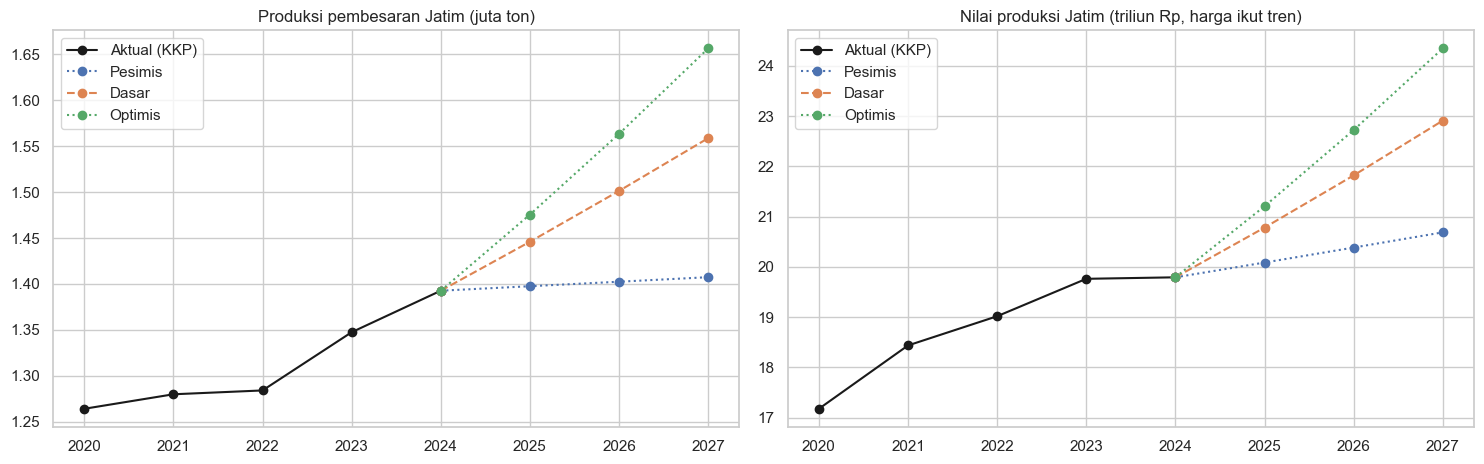

Catatan: proyeksi 2026-2027 murni ekstrapolasi tren — bukan ramalan pasti.


In [12]:
if M3_OK:
    fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
    for a, col, hcol, ttl, div in [(ax[0], 'produksi_ton', 'produksi_ton', 'Produksi pembesaran Jatim (juta ton)', 1e6), (ax[1], 'nilai_juta_harga_tren', 'nilai_juta', 'Nilai produksi Jatim (triliun Rp, harga ikut tren)', 1e6)]:
        a.plot(hist.tahun, hist[hcol] / div, 'ko-', label='Aktual (KKP)')
        for sk, st in [('Pesimis', ':'), ('Dasar', '--'), ('Optimis', ':')]:
            d_ = prov[prov.skenario == sk]; a.plot([LAST] + d_.tahun.tolist(), [hist[hcol].iloc[-1] / div] + (d_[col] / div).tolist(), st, marker='o', label=sk)
        a.set_title(ttl); a.legend(); a.set_xticks(list(range(YEARS[0], HORIZON[-1] + 1)))
    plt.tight_layout(); plt.savefig(FIG / '04_proyeksi.png', dpi=110); plt.show()
    print(f'Catatan: proyeksi {HORIZON[1]}-{HORIZON[2]} murni ekstrapolasi tren — bukan ramalan pasti.')

## Simulator What-If (untuk dashboard)
`nilai_baru = nilai_dasar × (1 + Δvolume)^elastisitas`. Dashboard saat ini memakai pendekatan linear `nilai × (1 + Δ × elastisitas)`; untuk Δ ≤ 100% selisihnya sangat kecil (mis. +100%: 1,97× vs 1,96×), sehingga **elastisitas dari M1 bisa dipakai langsung** tanpa mengubah tampilan.

In [13]:
BASE_NILAI = float(pan[pan.tahun == LAST].nilai_juta.sum()); BASE_PROD = float(pan[pan.tahun == LAST].produksi_ton.sum()); e_pt, e_lo, e_hi = el[True]
def simulasi(delta_pct, base=BASE_NILAI):
    f = 1 + delta_pct / 100; lohi = sorted([base * f ** e_lo / 1e6, base * f ** e_hi / 1e6])
    return {'delta_volume_pct': delta_pct, 'nilai_baru_Rp_T': base * f ** e_pt / 1e6, 'nilai_batas_bawah_Rp_T': lohi[0], 'nilai_batas_atas_Rp_T': lohi[1], 'tambahan_Rp_T': base * (f ** e_pt - 1) / 1e6}
sim = pd.DataFrame([simulasi(x) for x in [-20, -10, -5, 5, 10, 15, 20, 30]]); display(sim.round(2))
print(f'Dasar {LAST}: nilai Rp {BASE_NILAI / 1e6:.2f} T, produksi {BASE_PROD:,.0f} ton | elastisitas {e_pt:.3f} (CI {e_lo:.3f}-{e_hi:.3f})')
json.dump({'elastisitas': e_pt, 'ci95': [e_lo, e_hi], 'tahun_dasar': LAST, 'base_nilai_juta': BASE_NILAI, 'base_produksi_ton': BASE_PROD, 'cv_r2_M1': float(res1.loc[best1, 'R2_log']), 'rumus': 'nilai_baru = nilai_dasar * (1 + delta)^elastisitas'}, open(REP / 'scenario_params.json', 'w'), indent=2)
sim.to_csv(REP / 'scenario_table.csv', index=False)

,delta_volume_pct,nilai_baru_Rp_T,nilai_batas_bawah_Rp_T,nilai_batas_atas_Rp_T,tambahan_Rp_T
0,-20,15.93,15.87,15.98,-3.87
1,-10,17.86,17.83,17.89,-1.93
2,-5,18.83,18.81,18.84,-0.96
3,5,20.75,20.74,20.77,0.96
4,10,21.72,21.69,21.75,1.92
5,15,22.68,22.63,22.73,2.89
6,20,23.64,23.57,23.71,3.84
7,30,25.55,25.45,25.66,5.76


Dasar 2024: nilai Rp 19.79 T, produksi 1,392,702 ton | elastisitas 0.974 (CI 0.959-0.990)


## Ringkasan & penyimpanan (skema dashboard)
`regression_eval.csv` dibaca dashboard dengan kolom: `dataset`, `model`, `cv_r2_mean`, `r2_test`, `coef`.
* `cv_r2_mean` = R² grouped-CV pada skala log; `r2_test` = R² out-of-fold pada skala asli (Rp juta / ton);
* `coef` = elastisitas log-log **(dengan komoditas** untuk model yang memuat komoditas, **tanpa** untuk "Volume saja"). Dashboard membaca `coef` baris terbaik sebagai elastisitas simulator, jadi kolom ini **harus terisi** di baris terbaik.
* Dataset pertama di file = dataset utama dashboard → M1 ditulis lebih dulu.

In [14]:
rows = []
for nm in res1.index: rows.append({'dataset': 'nilai_vs_volume', 'model': nm, 'cv_r2_mean': res1.loc[nm, 'R2_log'], 'r2_test': res1.loc[nm, 'R2_asli'], 'coef': el[('komoditas' in nm)][0], 'medape': res1.loc[nm, 'medAPE'], 'rmse_log': res1.loc[nm, 'RMSE_log'], 'n': len(rk)})
if M2_OK:
    sc2 = res2_tab.drop('Baseline rata-rata'); sc2['set'] = [i.split(' | ')[0] for i in sc2.index]
    for s_, grp in sc2.groupby('set', sort=False):
        b = grp.R2_log.idxmax(); rows.append({'dataset': 'produksi_struktural', 'model': b.replace(' | ', ' / '), 'cv_r2_mean': grp.loc[b, 'R2_log'], 'r2_test': grp.loc[b, 'R2_asli'], 'coef': np.nan, 'medape': grp.loc[b, 'medAPE'], 'rmse_log': grp.loc[b, 'RMSE_log'], 'n': len(d2c)})
reg_eval = pd.DataFrame(rows); reg_eval.to_csv(REP / 'regression_eval.csv', index=False); display(reg_eval.round(3))
assert reg_eval[reg_eval.dataset == 'nilai_vs_volume'].sort_values('cv_r2_mean', ascending=False).iloc[0].coef == reg_eval[reg_eval.dataset == 'nilai_vs_volume'].sort_values('cv_r2_mean', ascending=False).iloc[0].coef, 'coef baris terbaik kosong -> dashboard memakai elastisitas 1.0'

allres = pd.concat([res1.reset_index(), res2_tab.reset_index() if M2_OK else pd.DataFrame(), (agg3.reset_index().assign(tugas='M3 forecast 1 tahun (rolling-origin)') if M3_OK else pd.DataFrame())], ignore_index=True); allres.to_csv(REP / 'regression_eval_detail.csv', index=False)
pd.DataFrame([['M1 nilai ~ volume (tanpa komoditas)', 'elastisitas', *el[False]], ['M1 nilai ~ volume (dengan komoditas)', 'elastisitas', *el[True]]], columns=['model', 'parameter', 'estimasi', 'ci95_lo', 'ci95_hi']).to_csv(REP / 'regression_coef.csv', index=False)
joblib.dump(M1[best1][0].fit(rk[M1[best1][1]], y1), MODEL / 'regressor_M1_nilai.pkl')
if M2_OK:
    sn_, mn_ = best2.split(' | '); dfit = d2.dropna(subset=S[sn_]); joblib.dump({'model': Pipeline([('s', StandardScaler()), ('m', clone(MD[mn_]))]).fit(dfit[S[sn_]], dfit.l_produksi_ton.values), 'fitur': S[sn_], 'set': sn_}, MODEL / 'regressor_M2_produksi_struktural.pkl')
joblib.dump(final_obj, MODEL / 'forecast_M3.pkl')

ins = [f"M1 Nilai ~ volume + komoditas: CV-R2 {res1.loc[best1, 'R2_log']:.3f} (volume saja {res1.loc['Volume saja (Ridge)', 'R2_log']:.3f}); elastisitas {el[True][0]:.2f} (CI {el[True][1]:.2f}-{el[True][2]:.2f}).",
       (f"M2 Produksi struktural ({best2}): CV-R2 {res2_tab.loc[best2, 'R2_log']:.3f}, median APE {res2_tab.loc[best2, 'medAPE']:.0%} - EXPLANATORY (membandingkan kabupaten), TIDAK cocok untuk prediksi titik." if M2_OK else 'M2 dilewati (data kurang).'),
       (f"M3 Prakiraan 1 tahun: {FINAL3}; median APE rolling-origin {agg3.loc[FINAL3, 'medAPE']:.1%}. {alasan}." if M3_OK else 'M3 dilewati (butuh >=3 tahun data).')]
if len(v): ins.append(f'Validasi {LAST + 1} (opendata): median APE {ape.median():.1%} pada {len(v)} kabupaten.')
json.dump({'insights': ins}, open(REP / 'regression_insight.json', 'w'), ensure_ascii=False, indent=2)
model_row = {'data_hash': json.load(open(REP / 'run_meta.json'))['data_hash'], 'model_name': f'M1:{best1}', 'cv_r2': float(res1.loc[best1, 'R2_log']), 'notes': ' | '.join(ins)[:900]}
json.dump(model_row, open(REP / 'model_version_row.json', 'w'), ensure_ascii=False)
for s_ in ins: print('-', s_)

,dataset,model,cv_r2_mean,r2_test,coef,medape,rmse_log,n
0,nilai_vs_volume,Volume saja (Ridge),0.928,-2.305,0.944,0.342,0.779,1353
1,nilai_vs_volume,Volume + komoditas (Ridge),0.979,0.789,0.974,0.134,0.424,1353
2,nilai_vs_volume,Volume + komoditas (Huber),0.978,0.831,0.974,0.133,0.425,1353
3,nilai_vs_volume,Volume + komoditas (RandomForest),0.944,0.430,0.974,0.267,0.687,1353
4,produksi_struktural,S1 pembudidaya / Ridge,0.602,-0.056,NaN,0.778,1.322,190
5,produksi_struktural,S2 + komposisi komoditas / RandomForest,0.579,-0.028,NaN,0.693,1.358,190
6,produksi_struktural,S3 + habitat / RandomForest,0.573,-0.023,NaN,0.678,1.368,190


- M1 Nilai ~ volume + komoditas: CV-R2 0.979 (volume saja 0.928); elastisitas 0.97 (CI 0.96-0.99).
- M2 Produksi struktural (S1 pembudidaya | Ridge): CV-R2 0.602, median APE 78% - EXPLANATORY (membandingkan kabupaten), TIDAK cocok untuk prediksi titik.
- M3 Prakiraan 1 tahun: Naif + rata-rata pertumbuhan; median APE rolling-origin 2.8%. model ML tidak mengungguli baseline >=10% (2.891% vs 2.779%) -> baseline (lebih sederhana, sama akurat).
- Validasi 2025 (opendata): median APE 2.3% pada 38 kabupaten.


## Batasan yang harus dikomunikasikan
- Data hanya beberapa tahun × puluhan kabupaten: M3 dilatih pada ratusan baris saja; interval 80% berasal dari galat rolling-origin yang juga kecil sampelnya.
- M1 bertumpu pada identitas nilai = volume × harga; R² tinggi bukan bukti "kemampuan prediksi".
- Data tahun baru dari opendata (di luar KKP) belum tentu final; dipakai hanya sebagai cek kewajaran.
- Luas lahan dipakai M2 **hanya pada tahun/kabupaten yang valid** dan hanya bila terbukti membantu di CV; bila tidak, set sederhana yang dipilih.